In [ ]:
# @title
!pip -q install kagglehub

import os
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import torch
from torch import nn, optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

In [ ]:
# @title
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo usado:", device)

NUM_EPOCHS = 10
BATCH_SIZE = 32
IMG_SIZE = 128

Dispositivo usado: cuda


In [ ]:
# @title
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "puneet6060/intel-image-classification"
)

print(dataset_path)

train_original = os.path.join(
    dataset_path,
    "seg_train",
    "seg_train"
)

test_original = os.path.join(
    dataset_path,
    "seg_test",
    "seg_test"
)

print("TRAIN:", train_original)
print("TEST:", test_original)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification
TRAIN: /kaggle/input/intel-image-classification/seg_train/seg_train
TEST: /kaggle/input/intel-image-classification/seg_test/seg_test


In [ ]:
# @title
selected_classes = [
    "buildings",
    "forest",
    "glacier",
    "mountain",
    "sea",
    "street"
]

filtered_dataset_dir = "/content/intel_dataset"

if os.path.exists(filtered_dataset_dir):
    shutil.rmtree(filtered_dataset_dir)

random.seed(SEED)

for class_name in selected_classes:

    class_dir = os.path.join(
        train_original,
        class_name
    )

    images = [
        os.path.join(class_dir, img)
        for img in os.listdir(class_dir)
        if img.lower().endswith(".jpg")
    ]

    random.shuffle(images)

    train_images = images[:1000]
    val_images = images[1000:1200]

    for split_name, split_images in {
        "train": train_images,
        "validation": val_images
    }.items():

        dst_dir = os.path.join(
            filtered_dataset_dir,
            split_name,
            class_name
        )

        os.makedirs(dst_dir, exist_ok=True)

        for src in split_images:

            shutil.copy2(
                src,
                os.path.join(
                    dst_dir,
                    os.path.basename(src)
                )
            )

for class_name in selected_classes:

    src_dir = os.path.join(
        test_original,
        class_name
    )

    dst_dir = os.path.join(
        filtered_dataset_dir,
        "test",
        class_name
    )

    shutil.copytree(
        src_dir,
        dst_dir
    )

print("Dataset preparado.")

Dataset preparado.


In [ ]:
# @title
for split in [
    "train",
    "validation",
    "test"
]:

    print("\n" + split.upper())

    split_dir = os.path.join(
        filtered_dataset_dir,
        split
    )

    total = 0

    for class_name in selected_classes:

        class_dir = os.path.join(
            split_dir,
            class_name
        )

        num_images = len(
            os.listdir(class_dir)
        )

        total += num_images

        print(
            class_name,
            ":",
            num_images
        )

    print("TOTAL:", total)


TRAIN
buildings : 1000
forest : 1000
glacier : 1000
mountain : 1000
sea : 1000
street : 1000
TOTAL: 6000

VALIDATION
buildings : 200
forest : 200
glacier : 200
mountain : 200
sea : 200
street : 200
TOTAL: 1200

TEST
buildings : 437
forest : 474
glacier : 553
mountain : 525
sea : 510
street : 501
TOTAL: 3000


In [ ]:
# @title
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_val_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
# @title
train_dir = os.path.join(
    filtered_dataset_dir,
    "train"
)

val_dir = os.path.join(
    filtered_dataset_dir,
    "validation"
)

test_dir = os.path.join(
    filtered_dataset_dir,
    "test"
)

train_dataset = datasets.ImageFolder(
    train_dir,
    transform=transform_train
)

val_dataset = datasets.ImageFolder(
    val_dir,
    transform=transform_val_test
)

test_dataset = datasets.ImageFolder(
    test_dir,
    transform=transform_val_test
)

class_names = train_dataset.classes
num_classes = len(class_names)

print("Clases:", class_names)
print("Número de clases:", num_classes)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

Clases: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
Número de clases: 6
Train: 6000
Validation: 1200
Test: 3000


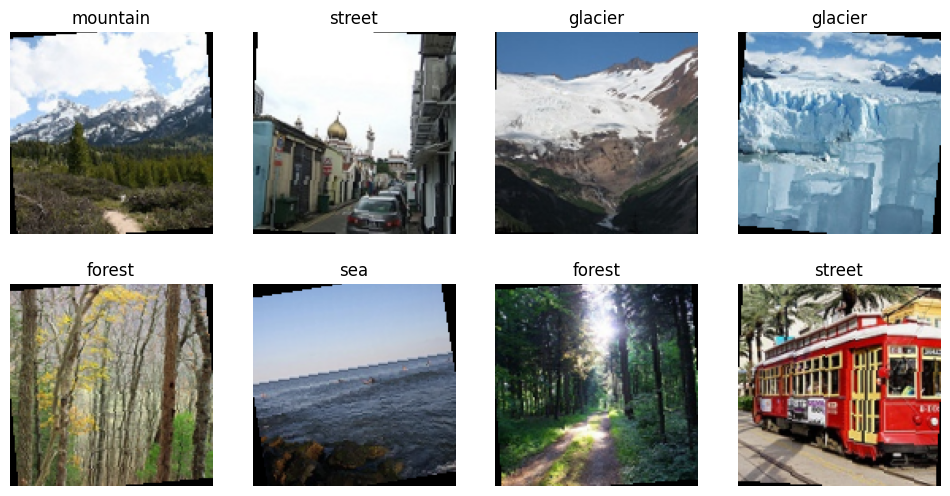

In [ ]:
def imshow_batch(images, labels):
    plt.figure(figsize=(12, 6))

    for i in range(8):
        img = images[i].permute(1, 2, 0)

        mean = torch.tensor([0.485, 0.456, 0.406])
        std = torch.tensor([0.229, 0.224, 0.225])

        img = img * std + mean
        img = torch.clamp(img, 0, 1)

        plt.subplot(2, 4, i + 1)
        plt.imshow(img)
        plt.title(class_names[labels[i]])
        plt.axis("off")

    plt.show()

images, labels = next(iter(train_loader))
imshow_batch(images, labels)

In [ ]:
def train_model(model, criterion, optimizer, train_loader_used, val_loader_used, num_epochs=NUM_EPOCHS):
    model = model.to(device)

    train_losses = []
    val_losses = []
    train_accs = []
    val_accs = []

    for epoch in range(num_epochs):
        model.train()

        running_loss = 0.0
        correct_train = 0
        total_train = 0

        for images, labels in train_loader_used:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader_used)
        train_acc = 100 * correct_train / total_train

        model.eval()

        running_val_loss = 0.0
        correct_val = 0
        total_val = 0

        with torch.no_grad():
            for images, labels in val_loader_used:
                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)
                loss = criterion(outputs, labels)

                running_val_loss += loss.item()

                _, predicted = torch.max(outputs, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        val_loss = running_val_loss / len(val_loader_used)
        val_acc = 100 * correct_val / total_val

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        train_accs.append(train_acc)
        val_accs.append(val_acc)

        print(f"Época {epoch+1}/{num_epochs} | "
              f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    history = {
        "train_losses": train_losses,
        "val_losses": val_losses,
        "train_accs": train_accs,
        "val_accs": val_accs
    }

    return model, history


def plot_history(history, title):
    plt.figure()
    plt.plot(history["train_losses"], label="Train Loss")
    plt.plot(history["val_losses"], label="Validation Loss")
    plt.title(f"Loss - {title}")
    plt.xlabel("Época")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

    plt.figure()
    plt.plot(history["train_accs"], label="Train Accuracy")
    plt.plot(history["val_accs"], label="Validation Accuracy")
    plt.title(f"Accuracy - {title}")
    plt.xlabel("Época")
    plt.ylabel("Accuracy (%)")
    plt.legend()
    plt.show()


def evaluate_model(model, loader, title):
    model.eval()

    all_preds = []
    all_labels = []

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_preds.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    acc = 100 * correct / total

    print(f"\nAccuracy final de {title}: {acc:.2f}%\n")

    cm = confusion_matrix(all_labels, all_preds)

    fig, ax = plt.subplots(figsize=(9, 9))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, xticks_rotation=45, values_format="d")
    plt.title(f"Matriz de confusión - {title}")
    plt.show()

    print(classification_report(all_labels, all_preds, target_names=class_names))

    return acc

Época 1/10 | Train Loss: 1.1086 | Train Acc: 57.57% | Val Loss: 0.9377 | Val Acc: 63.08%
Época 2/10 | Train Loss: 0.7608 | Train Acc: 71.47% | Val Loss: 0.7477 | Val Acc: 73.50%
Época 3/10 | Train Loss: 0.6240 | Train Acc: 76.68% | Val Loss: 0.6677 | Val Acc: 77.08%
Época 4/10 | Train Loss: 0.5445 | Train Acc: 80.43% | Val Loss: 0.5607 | Val Acc: 79.75%
Época 5/10 | Train Loss: 0.4995 | Train Acc: 81.80% | Val Loss: 0.5258 | Val Acc: 82.42%
Época 6/10 | Train Loss: 0.4110 | Train Acc: 85.25% | Val Loss: 0.5267 | Val Acc: 81.33%
Época 7/10 | Train Loss: 0.3828 | Train Acc: 86.23% | Val Loss: 0.5446 | Val Acc: 82.50%
Época 8/10 | Train Loss: 0.3284 | Train Acc: 88.02% | Val Loss: 0.5513 | Val Acc: 81.42%
Época 9/10 | Train Loss: 0.3255 | Train Acc: 88.08% | Val Loss: 0.5974 | Val Acc: 81.50%
Época 10/10 | Train Loss: 0.2755 | Train Acc: 89.62% | Val Loss: 0.6578 | Val Acc: 80.25%


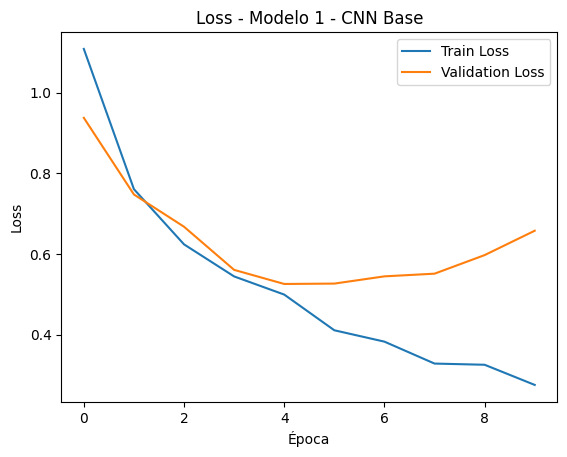

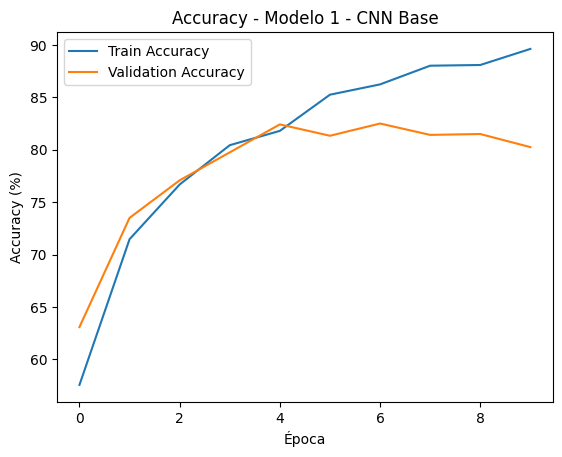


Accuracy final de Modelo 1 - CNN Base: 80.25%



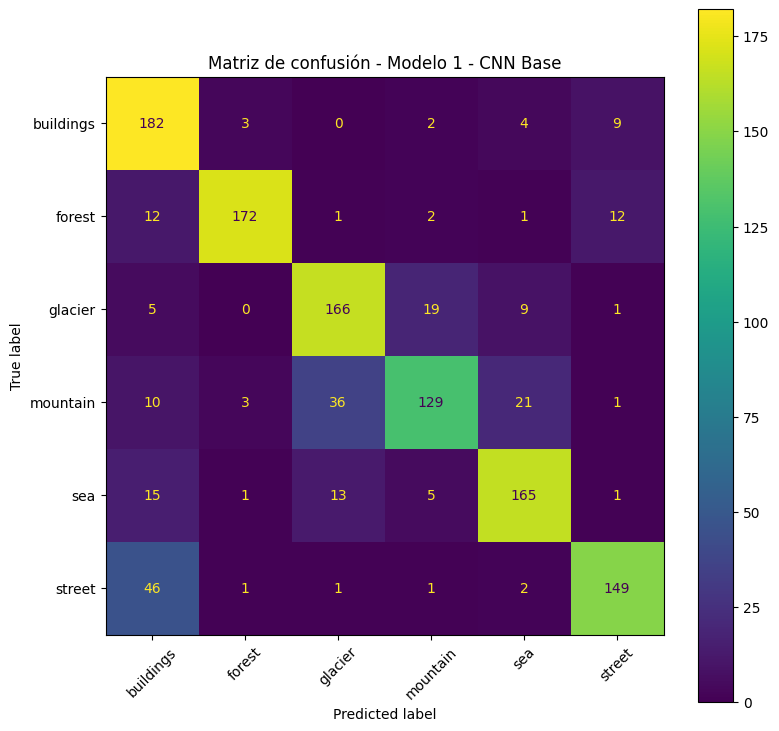

              precision    recall  f1-score   support

   buildings       0.67      0.91      0.77       200
      forest       0.96      0.86      0.91       200
     glacier       0.76      0.83      0.80       200
    mountain       0.82      0.65      0.72       200
         sea       0.82      0.82      0.82       200
      street       0.86      0.74      0.80       200

    accuracy                           0.80      1200
   macro avg       0.81      0.80      0.80      1200
weighted avg       0.81      0.80      0.80      1200



In [ ]:
class Modelo1_CNNBase(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 16 * 16, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model1 = Modelo1_CNNBase(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.parameters(), lr=0.001)

model1, history1 = train_model(model1, criterion, optimizer, train_loader, val_loader)
plot_history(history1, "Modelo 1 - CNN Base")
acc1 = evaluate_model(model1, val_loader, "Modelo 1 - CNN Base")

Modelo 1 - CNN Base
Cambios realizados

Se utilizó una red convolucional básica formada por tres capas convolucionales con 32, 64 y 128 filtros respectivamente, seguidas de una capa totalmente conectada de 512 neuronas. Se empleó un learning rate de 0.001 y no se utilizaron técnicas de regularización como Dropout o Batch Normalization.

Este modelo se utilizó como punto de partida para comparar el efecto de las modificaciones realizadas en los modelos posteriores.

Análisis de las gráficas

Durante las primeras épocas tanto la pérdida de entrenamiento como la pérdida de validación disminuyen de forma constante, lo que indica que la red está aprendiendo correctamente.

Sin embargo, a partir de aproximadamente la época 5 se observa que la pérdida de entrenamiento continúa disminuyendo mientras que la pérdida de validación comienza a aumentar. Además, la precisión de entrenamiento sigue creciendo hasta alcanzar aproximadamente el 90%, mientras que la precisión de validación se estabiliza alrededor del 80%.

Este comportamiento indica la aparición de overfitting, ya que el modelo continúa mejorando sobre los datos de entrenamiento pero pierde capacidad de generalización sobre datos no vistos.

Matriz de confusión

Las clases Forest, Glacier y Sea presentan buenos resultados de clasificación. Las principales confusiones aparecen entre Mountain y Glacier, así como entre Street y Buildings, debido a que visualmente comparten características similares.

Resultado

Accuracy final: 80.25%

Conclusión

El modelo consigue un rendimiento aceptable, pero muestra síntomas claros de overfitting a partir de la mitad del entrenamiento.

Época 1/10 | Train Loss: 1.1036 | Train Acc: 57.00% | Val Loss: 0.9309 | Val Acc: 65.33%
Época 2/10 | Train Loss: 0.7556 | Train Acc: 72.10% | Val Loss: 0.7416 | Val Acc: 73.67%
Época 3/10 | Train Loss: 0.6286 | Train Acc: 77.07% | Val Loss: 0.6840 | Val Acc: 74.75%
Época 4/10 | Train Loss: 0.5439 | Train Acc: 80.02% | Val Loss: 0.6397 | Val Acc: 78.50%
Época 5/10 | Train Loss: 0.4767 | Train Acc: 82.13% | Val Loss: 0.5732 | Val Acc: 80.17%
Época 6/10 | Train Loss: 0.4133 | Train Acc: 84.63% | Val Loss: 0.6841 | Val Acc: 76.75%
Época 7/10 | Train Loss: 0.3730 | Train Acc: 86.10% | Val Loss: 0.6085 | Val Acc: 80.92%
Época 8/10 | Train Loss: 0.3139 | Train Acc: 88.65% | Val Loss: 0.5471 | Val Acc: 82.00%
Época 9/10 | Train Loss: 0.2743 | Train Acc: 90.28% | Val Loss: 0.5409 | Val Acc: 82.58%
Época 10/10 | Train Loss: 0.2466 | Train Acc: 91.12% | Val Loss: 0.5528 | Val Acc: 82.17%


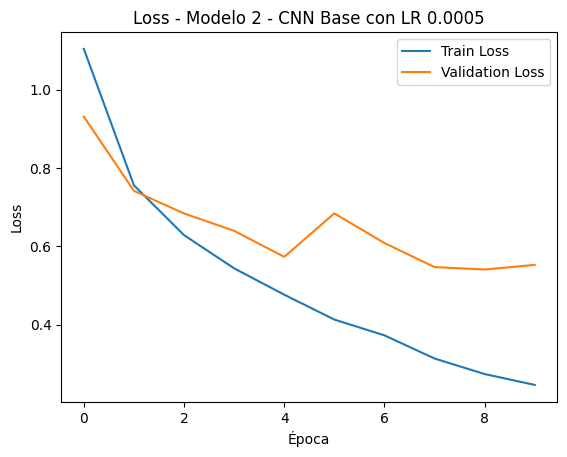

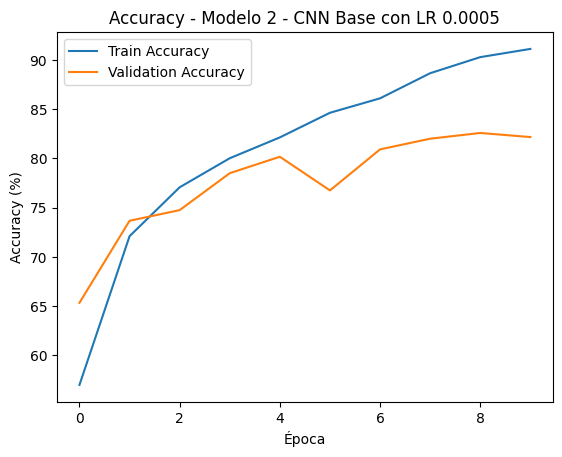


Accuracy final de Modelo 2 - CNN Base con LR 0.0005: 82.17%



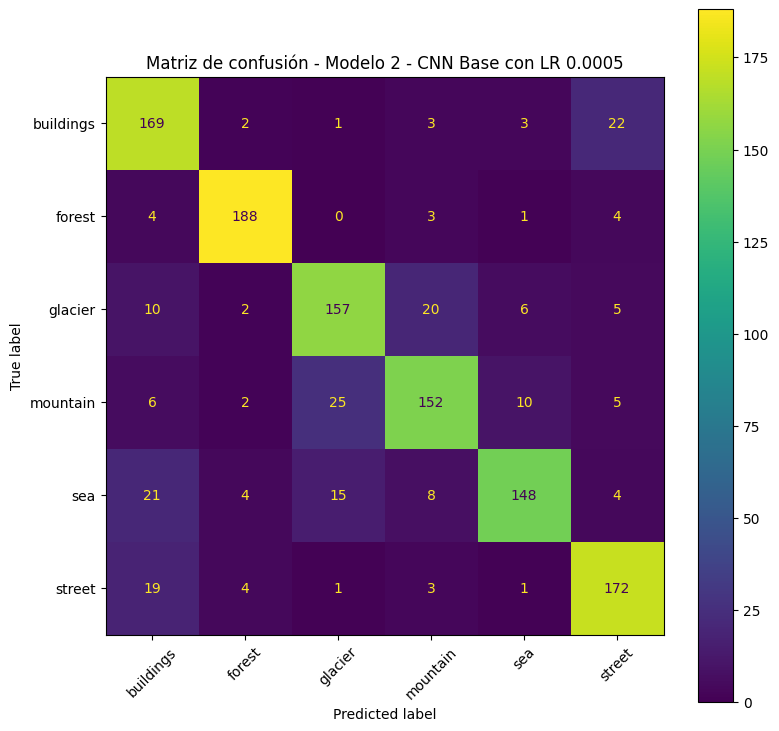

              precision    recall  f1-score   support

   buildings       0.74      0.84      0.79       200
      forest       0.93      0.94      0.94       200
     glacier       0.79      0.79      0.79       200
    mountain       0.80      0.76      0.78       200
         sea       0.88      0.74      0.80       200
      street       0.81      0.86      0.83       200

    accuracy                           0.82      1200
   macro avg       0.82      0.82      0.82      1200
weighted avg       0.82      0.82      0.82      1200



In [ ]:
class Modelo2_CNNLearningRateBajo(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 16 * 16, 512)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model2 = Modelo2_CNNLearningRateBajo(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model2.parameters(), lr=0.0005)

model2, history2 = train_model(model2, criterion, optimizer, train_loader, val_loader)
plot_history(history2, "Modelo 2 - CNN Base con LR 0.0005")
acc2 = evaluate_model(model2, val_loader, "Modelo 2 - CNN Base con LR 0.0005")

Modelo 2 - CNN Base con Learning Rate 0.0005
Cambios realizados

Se mantuvo exactamente la misma arquitectura que en el Modelo 1, modificando únicamente el learning rate, que pasó de 0.001 a 0.0005.

Justificación

El objetivo era comprobar si un aprendizaje más lento permitía obtener una convergencia más estable y una mejor capacidad de generalización.

Análisis de las gráficas

La pérdida disminuye de forma más suave y estable que en el modelo base. La precisión aumenta progresivamente y se observan menos oscilaciones durante el entrenamiento.

Aunque sigue existiendo cierta diferencia entre entrenamiento y validación, el comportamiento es más estable que en el Modelo 1.

Matriz de confusión

Se observa una mejora general en varias clases, especialmente Forest y Street. Las confusiones entre Glacier y Mountain continúan existiendo, aunque son algo menores.

Resultado

Accuracy final: 82.17%

Conclusión

Reducir el learning rate produjo una mejora de aproximadamente dos puntos porcentuales respecto al modelo base. Un aprendizaje más lento permitió encontrar una solución más estable y con mejor capacidad de generalización.

Época 1/10 | Train Loss: 1.1695 | Train Acc: 55.07% | Val Loss: 0.8792 | Val Acc: 67.50%
Época 2/10 | Train Loss: 0.8059 | Train Acc: 69.57% | Val Loss: 0.7255 | Val Acc: 73.58%
Época 3/10 | Train Loss: 0.6913 | Train Acc: 74.37% | Val Loss: 0.6853 | Val Acc: 75.75%
Época 4/10 | Train Loss: 0.5998 | Train Acc: 78.42% | Val Loss: 0.6404 | Val Acc: 76.92%
Época 5/10 | Train Loss: 0.5293 | Train Acc: 80.62% | Val Loss: 0.6355 | Val Acc: 77.50%
Época 6/10 | Train Loss: 0.4755 | Train Acc: 82.90% | Val Loss: 0.5930 | Val Acc: 80.58%
Época 7/10 | Train Loss: 0.4208 | Train Acc: 84.85% | Val Loss: 0.5677 | Val Acc: 81.17%
Época 8/10 | Train Loss: 0.3875 | Train Acc: 85.87% | Val Loss: 0.5841 | Val Acc: 81.33%
Época 9/10 | Train Loss: 0.3550 | Train Acc: 86.82% | Val Loss: 0.6030 | Val Acc: 80.67%
Época 10/10 | Train Loss: 0.2959 | Train Acc: 89.33% | Val Loss: 0.6161 | Val Acc: 82.08%


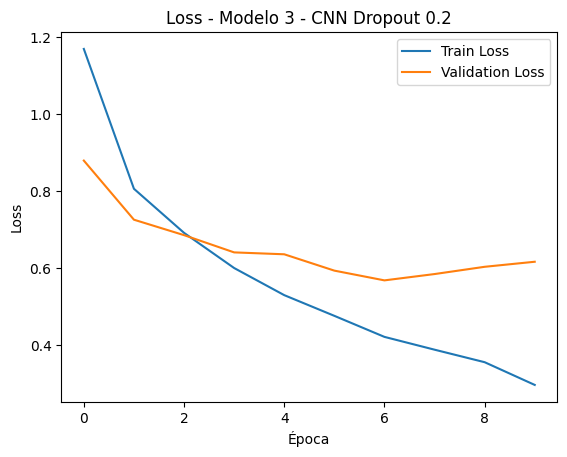

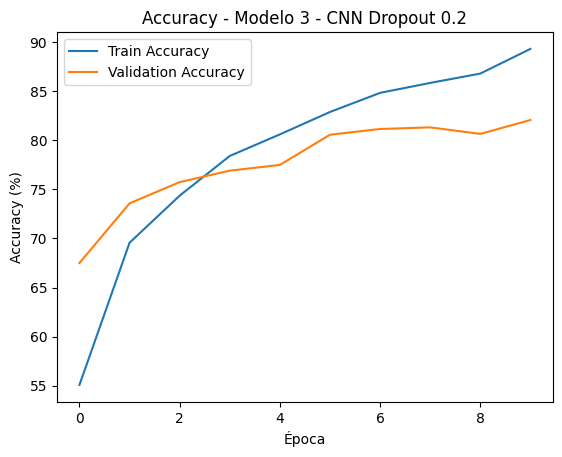


Accuracy final de Modelo 3 - CNN Dropout 0.2: 82.08%



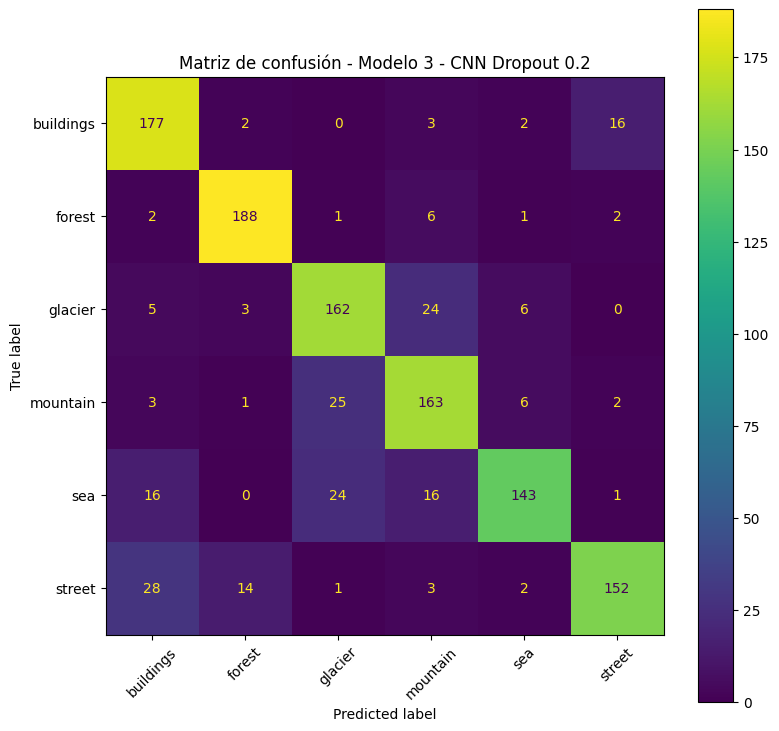

              precision    recall  f1-score   support

   buildings       0.77      0.89      0.82       200
      forest       0.90      0.94      0.92       200
     glacier       0.76      0.81      0.78       200
    mountain       0.76      0.81      0.79       200
         sea       0.89      0.71      0.79       200
      street       0.88      0.76      0.82       200

    accuracy                           0.82      1200
   macro avg       0.83      0.82      0.82      1200
weighted avg       0.83      0.82      0.82      1200



In [ ]:
class Modelo3_CNNDropoutSuave(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 16 * 16, 512)
        self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model3 = Modelo3_CNNDropoutSuave(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model3.parameters(), lr=0.001)

model3, history3 = train_model(model3, criterion, optimizer, train_loader, val_loader)
plot_history(history3, "Modelo 3 - CNN Dropout 0.2")
acc3 = evaluate_model(model3, val_loader, "Modelo 3 - CNN Dropout 0.2")

Modelo 3 - CNN con Dropout 0.2
Cambios realizados

Se añadió una capa Dropout con probabilidad 0.2 después de la capa totalmente conectada.

Justificación

El objetivo era reducir el overfitting detectado en el modelo base obligando a la red a no depender excesivamente de determinadas neuronas.

Análisis de las gráficas

La diferencia entre entrenamiento y validación es menor que en el Modelo 1. La precisión de validación se mantiene más estable y la pérdida de validación aumenta más lentamente.

Esto indica que la regularización está ayudando a mejorar la capacidad de generalización.

Matriz de confusión

Las clases Forest y Buildings muestran una ligera mejora. Las confusiones entre Glacier y Mountain siguen siendo las más frecuentes.

Resultado

Accuracy final: 82.08%

Conclusión

La incorporación de un Dropout moderado permitió reducir parcialmente el overfitting sin perjudicar el aprendizaje de la red.

Época 1/10 | Train Loss: 1.2401 | Train Acc: 52.80% | Val Loss: 0.9632 | Val Acc: 61.58%
Época 2/10 | Train Loss: 0.8846 | Train Acc: 67.08% | Val Loss: 0.8246 | Val Acc: 70.17%
Época 3/10 | Train Loss: 0.7580 | Train Acc: 71.20% | Val Loss: 0.6363 | Val Acc: 78.08%
Época 4/10 | Train Loss: 0.6508 | Train Acc: 75.98% | Val Loss: 0.6117 | Val Acc: 78.33%
Época 5/10 | Train Loss: 0.5897 | Train Acc: 78.15% | Val Loss: 0.5694 | Val Acc: 79.58%
Época 6/10 | Train Loss: 0.5430 | Train Acc: 80.15% | Val Loss: 0.6000 | Val Acc: 78.67%
Época 7/10 | Train Loss: 0.4914 | Train Acc: 82.10% | Val Loss: 0.5073 | Val Acc: 82.00%
Época 8/10 | Train Loss: 0.4610 | Train Acc: 83.43% | Val Loss: 0.5513 | Val Acc: 80.58%
Época 9/10 | Train Loss: 0.4291 | Train Acc: 84.20% | Val Loss: 0.5380 | Val Acc: 81.08%
Época 10/10 | Train Loss: 0.3959 | Train Acc: 85.03% | Val Loss: 0.5840 | Val Acc: 80.08%


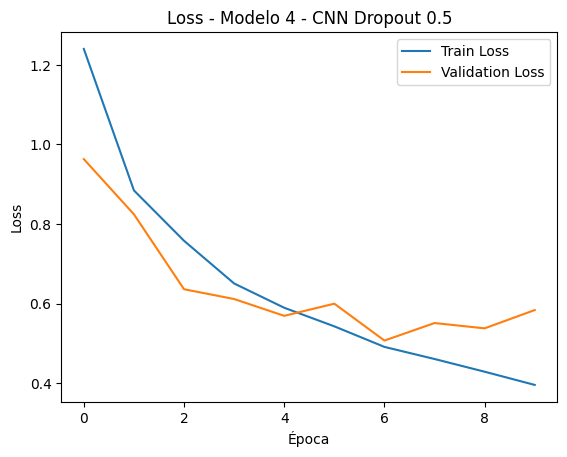

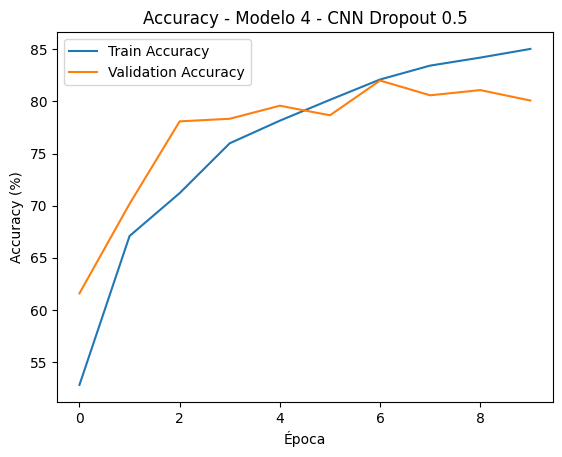


Accuracy final de Modelo 4 - CNN Dropout 0.5: 80.08%



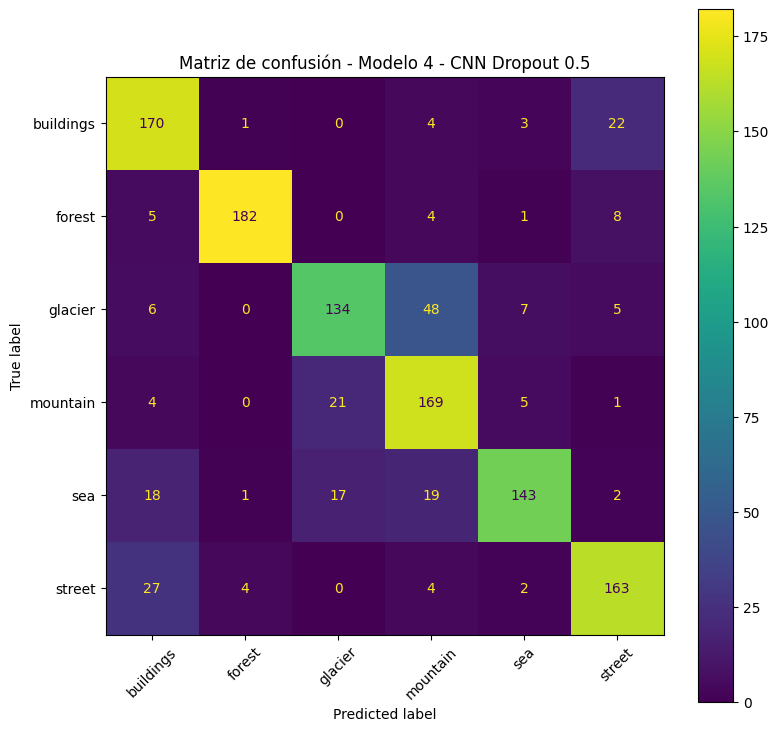

              precision    recall  f1-score   support

   buildings       0.74      0.85      0.79       200
      forest       0.97      0.91      0.94       200
     glacier       0.78      0.67      0.72       200
    mountain       0.68      0.84      0.75       200
         sea       0.89      0.71      0.79       200
      street       0.81      0.81      0.81       200

    accuracy                           0.80      1200
   macro avg       0.81      0.80      0.80      1200
weighted avg       0.81      0.80      0.80      1200



In [ ]:
class Modelo4_CNNDropoutFuerte(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(128 * 16 * 16, 512)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(512, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)

        return x


model4 = Modelo4_CNNDropoutFuerte(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model4.parameters(), lr=0.001)

model4, history4 = train_model(model4, criterion, optimizer, train_loader, val_loader)
plot_history(history4, "Modelo 4 - CNN Dropout 0.5")
acc4 = evaluate_model(model4, val_loader, "Modelo 4 - CNN Dropout 0.5")

Modelo 4 - CNN con Dropout 0.5
Cambios realizados

Se incrementó el valor del Dropout desde 0.2 hasta 0.5.

Justificación

Se pretendía analizar el efecto de una regularización más agresiva.

Análisis de las gráficas

La precisión de entrenamiento crece más lentamente y alcanza valores inferiores a los modelos anteriores. La pérdida disminuye de forma más lenta, indicando que la red tiene mayores dificultades para aprender.

Matriz de confusión

Las confusiones entre Glacier y Mountain aumentan notablemente. También aparecen más errores entre Buildings y Street.

Resultado

Accuracy final: 80.08%

Conclusión

El valor de Dropout utilizado resulta excesivo para este problema. Aunque reduce el overfitting, también limita la capacidad de aprendizaje de la red, produciendo cierto underfitting.

Época 1/10 | Train Loss: 1.0988 | Train Acc: 57.20% | Val Loss: 0.8527 | Val Acc: 68.00%
Época 2/10 | Train Loss: 0.7741 | Train Acc: 71.25% | Val Loss: 0.7334 | Val Acc: 74.25%
Época 3/10 | Train Loss: 0.6244 | Train Acc: 76.67% | Val Loss: 0.6300 | Val Acc: 77.08%
Época 4/10 | Train Loss: 0.5497 | Train Acc: 80.12% | Val Loss: 0.6647 | Val Acc: 74.75%
Época 5/10 | Train Loss: 0.5058 | Train Acc: 81.67% | Val Loss: 0.5550 | Val Acc: 80.42%
Época 6/10 | Train Loss: 0.4241 | Train Acc: 84.28% | Val Loss: 0.5946 | Val Acc: 79.67%
Época 7/10 | Train Loss: 0.3746 | Train Acc: 86.42% | Val Loss: 0.5518 | Val Acc: 80.50%
Época 8/10 | Train Loss: 0.3450 | Train Acc: 87.22% | Val Loss: 0.5474 | Val Acc: 82.00%
Época 9/10 | Train Loss: 0.3273 | Train Acc: 88.00% | Val Loss: 0.6136 | Val Acc: 81.17%
Época 10/10 | Train Loss: 0.2817 | Train Acc: 89.90% | Val Loss: 0.6322 | Val Acc: 78.58%


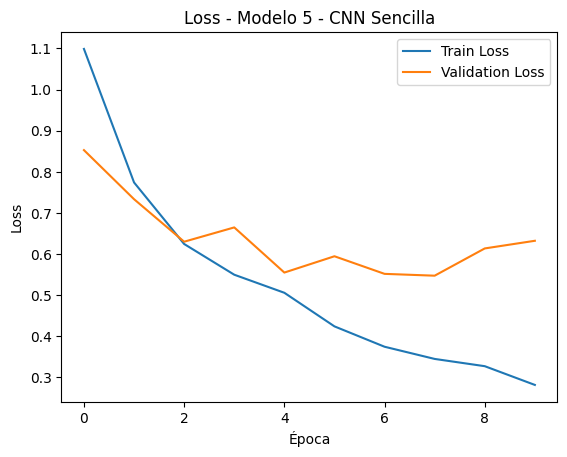

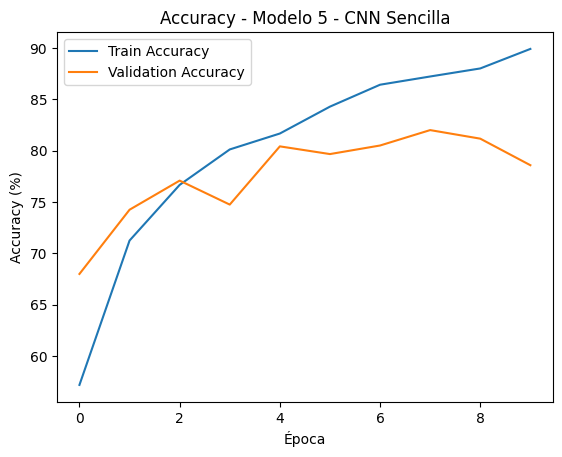


Accuracy final de Modelo 5 - CNN Sencilla: 78.58%



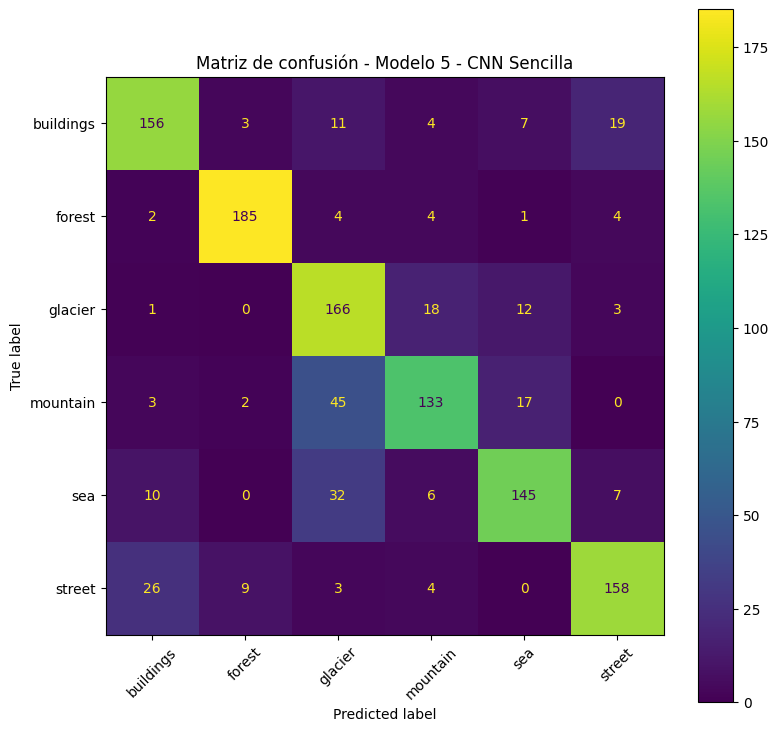

              precision    recall  f1-score   support

   buildings       0.79      0.78      0.78       200
      forest       0.93      0.93      0.93       200
     glacier       0.64      0.83      0.72       200
    mountain       0.79      0.67      0.72       200
         sea       0.80      0.72      0.76       200
      street       0.83      0.79      0.81       200

    accuracy                           0.79      1200
   macro avg       0.79      0.79      0.79      1200
weighted avg       0.79      0.79      0.79      1200



In [ ]:
class Modelo5_CNNSencilla(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(64 * 16 * 16, 256)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = self.fc2(x)

        return x


model5 = Modelo5_CNNSencilla(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model5.parameters(), lr=0.001)

model5, history5 = train_model(model5, criterion, optimizer, train_loader, val_loader)
plot_history(history5, "Modelo 5 - CNN Sencilla")
acc5 = evaluate_model(model5, val_loader, "Modelo 5 - CNN Sencilla")

Modelo 5 - CNN Sencilla
Cambios realizados

Se redujo el número de filtros de las capas convolucionales a 16, 32 y 64. Además, la capa totalmente conectada pasó de 512 a 256 neuronas.

Justificación

Se buscaba comprobar si una red más pequeña y menos compleja era suficiente para resolver el problema.

Análisis de las gráficas

La precisión aumenta correctamente durante las primeras épocas, pero se estabiliza antes que en los modelos anteriores. La pérdida de validación comienza a aumentar relativamente pronto.

Matriz de confusión

Se incrementan los errores especialmente en Buildings, Mountain y Sea, indicando que la red dispone de menos capacidad para extraer características relevantes.

Resultado

Accuracy final: 78.58%

Conclusión

La reducción de parámetros provoca una pérdida de rendimiento. El modelo presenta síntomas de underfitting debido a su limitada capacidad de representación.

Época 1/10 | Train Loss: 1.1434 | Train Acc: 53.73% | Val Loss: 0.9652 | Val Acc: 60.58%
Época 2/10 | Train Loss: 0.9041 | Train Acc: 64.57% | Val Loss: 0.8305 | Val Acc: 69.33%
Época 3/10 | Train Loss: 0.7456 | Train Acc: 71.73% | Val Loss: 0.7853 | Val Acc: 70.08%
Época 4/10 | Train Loss: 0.6266 | Train Acc: 77.32% | Val Loss: 0.6225 | Val Acc: 78.92%
Época 5/10 | Train Loss: 0.5515 | Train Acc: 80.43% | Val Loss: 0.5614 | Val Acc: 80.58%
Época 6/10 | Train Loss: 0.4862 | Train Acc: 83.00% | Val Loss: 0.4990 | Val Acc: 82.75%
Época 7/10 | Train Loss: 0.4558 | Train Acc: 83.63% | Val Loss: 0.6012 | Val Acc: 79.17%
Época 8/10 | Train Loss: 0.4187 | Train Acc: 84.63% | Val Loss: 0.5157 | Val Acc: 82.00%
Época 9/10 | Train Loss: 0.3961 | Train Acc: 86.10% | Val Loss: 0.5419 | Val Acc: 81.17%
Época 10/10 | Train Loss: 0.3488 | Train Acc: 86.88% | Val Loss: 0.5511 | Val Acc: 80.92%


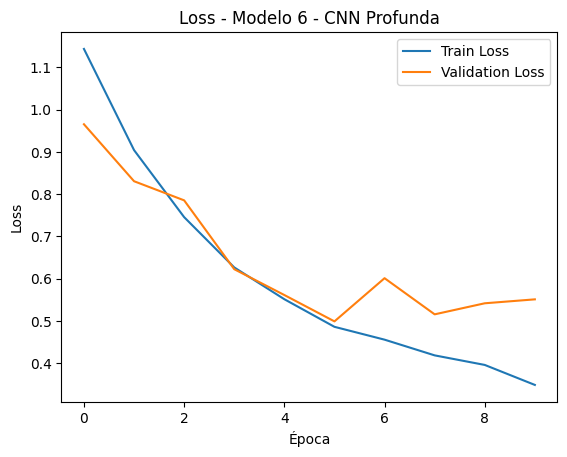

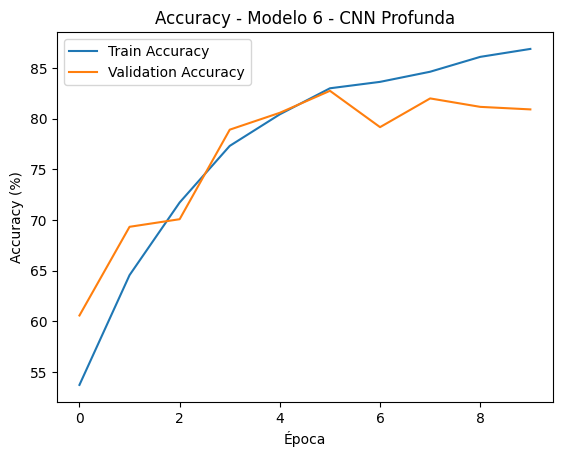


Accuracy final de Modelo 6 - CNN Profunda: 80.92%



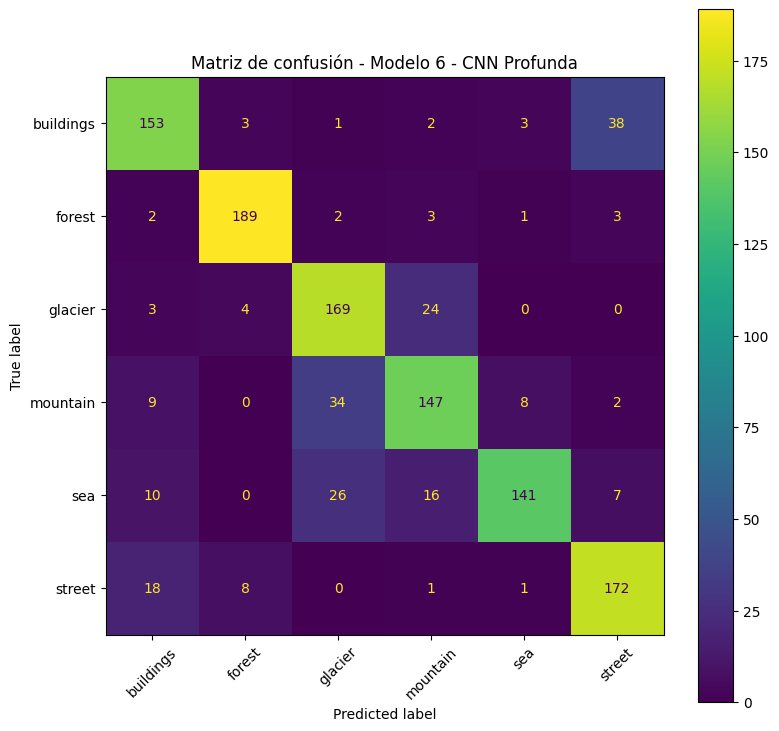

              precision    recall  f1-score   support

   buildings       0.78      0.77      0.77       200
      forest       0.93      0.94      0.94       200
     glacier       0.73      0.84      0.78       200
    mountain       0.76      0.73      0.75       200
         sea       0.92      0.70      0.80       200
      street       0.77      0.86      0.82       200

    accuracy                           0.81      1200
   macro avg       0.82      0.81      0.81      1200
weighted avg       0.82      0.81      0.81      1200



In [ ]:
class Modelo6_CNNProfunda(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv2d(128, 256, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(256 * 8 * 8, 512)
        self.fc2 = nn.Linear(512, 256)
        self.fc3 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.pool(torch.relu(self.conv3(x)))
        x = self.pool(torch.relu(self.conv4(x)))

        x = x.view(x.size(0), -1)

        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)

        return x


model6 = Modelo6_CNNProfunda(num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model6.parameters(), lr=0.001)

model6, history6 = train_model(model6, criterion, optimizer, train_loader, val_loader)
plot_history(history6, "Modelo 6 - CNN Profunda")
acc6 = evaluate_model(model6, val_loader, "Modelo 6 - CNN Profunda")

Modelo 6 - CNN Profunda
Cambios realizados

Se añadió una cuarta capa convolucional con 256 filtros y una capa totalmente conectada adicional de 256 neuronas.

Justificación

El objetivo era aumentar la capacidad de extracción de características y comprobar si una arquitectura más compleja obtenía mejores resultados.

Análisis de las gráficas

La precisión de entrenamiento continúa aumentando correctamente, pero la precisión de validación se estabiliza alrededor del 81%. La pérdida de validación deja de mejorar tras varias épocas.

Matriz de confusión

Las principales confusiones siguen apareciendo entre Glacier y Mountain, así como entre Buildings y Street.

Resultado

Accuracy final: 80.92%

Conclusión

Aumentar la profundidad de la red no produce mejoras significativas. La complejidad adicional no aporta suficiente información nueva para mejorar claramente el rendimiento.

DataLoaders de Transfer Learning preparados.
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 132MB/s]


Época 1/10 | Train Loss: 0.7725 | Train Acc: 74.32% | Val Loss: 0.4088 | Val Acc: 85.83%
Época 2/10 | Train Loss: 0.4165 | Train Acc: 86.42% | Val Loss: 0.3423 | Val Acc: 87.75%
Época 3/10 | Train Loss: 0.3643 | Train Acc: 87.58% | Val Loss: 0.3379 | Val Acc: 88.00%
Época 4/10 | Train Loss: 0.3479 | Train Acc: 87.88% | Val Loss: 0.3055 | Val Acc: 89.25%
Época 5/10 | Train Loss: 0.3179 | Train Acc: 88.73% | Val Loss: 0.3114 | Val Acc: 88.25%
Época 6/10 | Train Loss: 0.3096 | Train Acc: 89.07% | Val Loss: 0.2935 | Val Acc: 89.75%
Época 7/10 | Train Loss: 0.3066 | Train Acc: 88.57% | Val Loss: 0.3103 | Val Acc: 89.25%
Época 8/10 | Train Loss: 0.3021 | Train Acc: 88.98% | Val Loss: 0.3063 | Val Acc: 89.25%
Época 9/10 | Train Loss: 0.2918 | Train Acc: 89.33% | Val Loss: 0.2907 | Val Acc: 90.25%
Época 10/10 | Train Loss: 0.2785 | Train Acc: 90.10% | Val Loss: 0.3054 | Val Acc: 88.92%


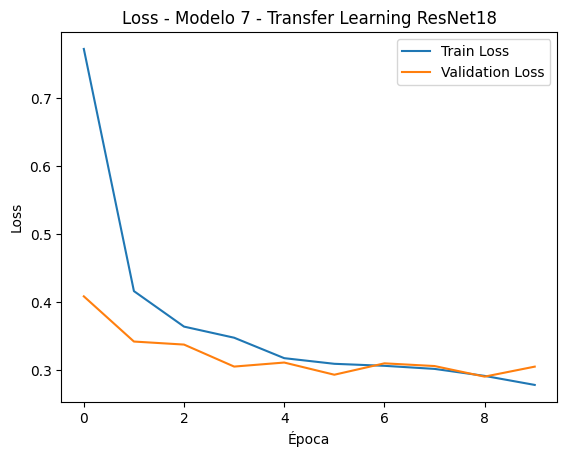

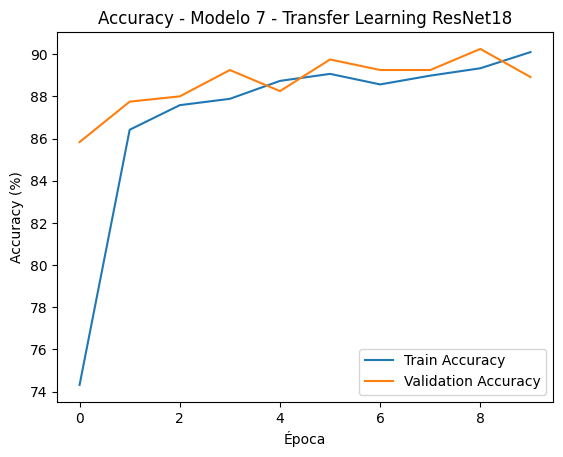


Accuracy final de Modelo 7 - Transfer Learning ResNet18: 88.92%



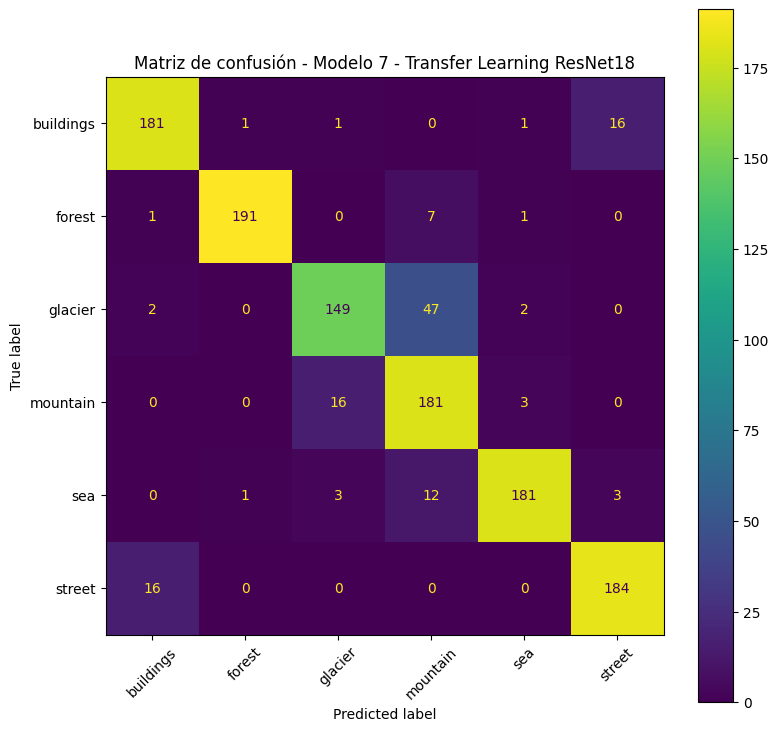

              precision    recall  f1-score   support

   buildings       0.91      0.91      0.91       200
      forest       0.99      0.95      0.97       200
     glacier       0.88      0.74      0.81       200
    mountain       0.73      0.91      0.81       200
         sea       0.96      0.91      0.93       200
      street       0.91      0.92      0.91       200

    accuracy                           0.89      1200
   macro avg       0.90      0.89      0.89      1200
weighted avg       0.90      0.89      0.89      1200



In [ ]:
IMG_SIZE_TL = 224

transform_train_tl = transforms.Compose([
    transforms.Resize((IMG_SIZE_TL, IMG_SIZE_TL)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

transform_val_test_tl = transforms.Compose([
    transforms.Resize((IMG_SIZE_TL, IMG_SIZE_TL)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset_tl = datasets.ImageFolder(train_dir, transform=transform_train_tl)
val_dataset_tl = datasets.ImageFolder(val_dir, transform=transform_val_test_tl)
test_dataset_tl = datasets.ImageFolder(test_dir, transform=transform_val_test_tl)

train_loader_tl = DataLoader(train_dataset_tl, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader_tl = DataLoader(val_dataset_tl, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader_tl = DataLoader(test_dataset_tl, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("DataLoaders de Transfer Learning preparados.")

model7 = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)

for param in model7.parameters():
    param.requires_grad = False

model7.fc = nn.Linear(model7.fc.in_features, num_classes)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model7.fc.parameters(), lr=0.001)

model7, history7 = train_model(model7, criterion, optimizer, train_loader_tl, val_loader_tl)
plot_history(history7, "Modelo 7 - Transfer Learning ResNet18")
acc7 = evaluate_model(model7, val_loader_tl, "Modelo 7 - Transfer Learning ResNet18")

Modelo 7 - Transfer Learning con ResNet18
Cambios realizados

Se sustituyó la CNN diseñada manualmente por una red ResNet18 preentrenada en ImageNet. Todas las capas fueron congeladas excepto la capa de salida, que fue adaptada al número de clases del problema.

Justificación

Se pretendía aprovechar características visuales aprendidas previamente a partir de millones de imágenes.

Análisis de las gráficas

Las curvas de entrenamiento y validación permanecen muy próximas durante todo el entrenamiento. La pérdida disminuye rápidamente y la precisión alcanza valores cercanos al 90%.

No aparecen síntomas importantes de overfitting.

Matriz de confusión

Las clases Forest, Sea y Street son clasificadas con gran precisión. Las únicas confusiones importantes siguen apareciendo entre Glacier y Mountain, que son visualmente muy similares.

Resultado

Accuracy en validación: 88.92%

Accuracy en test: 89.00%

Conclusión

El Transfer Learning proporciona claramente el mejor rendimiento de todos los modelos. La utilización de una red preentrenada permite obtener una mejora muy significativa respecto a las CNN diseñadas manualmente.

In [ ]:
resultados = {
    "Modelo 1 - CNN Base": acc1,
    "Modelo 2 - LR 0.0005": acc2,
    "Modelo 3 - Dropout 0.2": acc3,
    "Modelo 4 - Dropout 0.5": acc4,
    "Modelo 5 - CNN Sencilla": acc5,
    "Modelo 6 - CNN Profunda": acc6,
    "Modelo 7 - Transfer Learning": acc7
}

tabla_resultados = pd.DataFrame({
    "Modelo": list(resultados.keys()),
    "Accuracy validación (%)": list(resultados.values())
})

tabla_resultados = tabla_resultados.sort_values(
    by="Accuracy validación (%)",
    ascending=False
)

tabla_resultados

,Modelo,Accuracy validación (%)
6,Modelo 7 - Transfer Learning,88.916667
1,Modelo 2 - LR 0.0005,82.166667
2,Modelo 3 - Dropout 0.2,82.083333
5,Modelo 6 - CNN Profunda,80.916667
0,Modelo 1 - CNN Base,80.250000
3,Modelo 4 - Dropout 0.5,80.083333
4,Modelo 5 - CNN Sencilla,78.583333


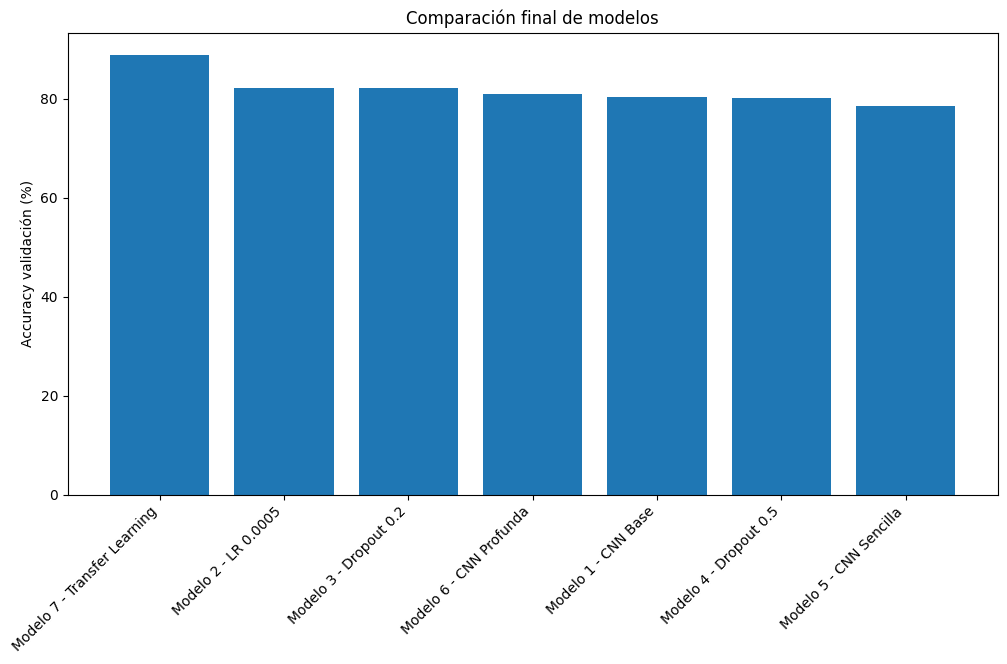

Mejor modelo:
Modelo 7 - Transfer Learning
Accuracy: 88.91666666666667

Accuracy final de Modelo 7 - Transfer Learning ResNet18 en Test: 89.00%



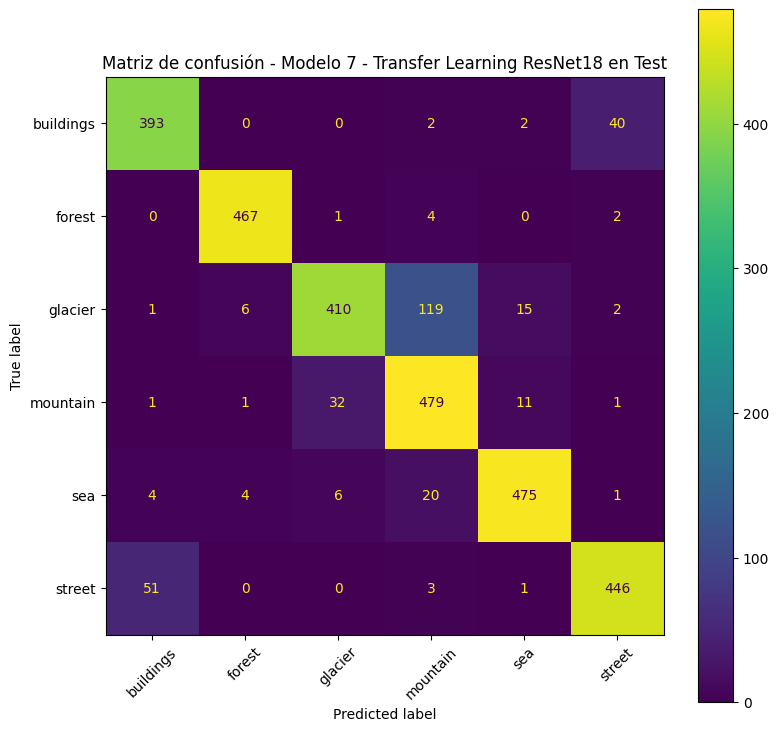

              precision    recall  f1-score   support

   buildings       0.87      0.90      0.89       437
      forest       0.98      0.99      0.98       474
     glacier       0.91      0.74      0.82       553
    mountain       0.76      0.91      0.83       525
         sea       0.94      0.93      0.94       510
      street       0.91      0.89      0.90       501

    accuracy                           0.89      3000
   macro avg       0.90      0.89      0.89      3000
weighted avg       0.90      0.89      0.89      3000



In [ ]:
plt.figure(figsize=(12, 6))
plt.bar(tabla_resultados["Modelo"], tabla_resultados["Accuracy validación (%)"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Accuracy validación (%)")
plt.title("Comparación final de modelos")
plt.show()

mejor_modelo = tabla_resultados.iloc[0]

print("Mejor modelo:")
print(mejor_modelo["Modelo"])
print("Accuracy:", mejor_modelo["Accuracy validación (%)"])


Conclusiones generales

El modelo base permitió identificar la aparición de overfitting a partir de la quinta época. La reducción del learning rate y la incorporación de un Dropout moderado fueron las modificaciones que produjeron las mayores mejoras entre las CNN diseñadas manualmente. Un Dropout excesivo redujo la capacidad de aprendizaje de la red, mientras que una arquitectura demasiado simple produjo underfitting. Aumentar la profundidad de la red no generó mejoras significativas. Finalmente, el uso de Transfer Learning mediante ResNet18 proporcionó el mejor resultado tanto en validación como en test, demostrando la ventaja de reutilizar modelos previamente entrenados para tareas de clasificación de imágenes.